# Feature Extraction, Aggregation, Flattening, and Stacking with AFX Module

This notebook demonstrates how to use the AFX package to extract, aggregate, flatten, and stack feature vectors from audio samples in the `data` folder.

In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import afx_audio as afx
from afx_audio.extractors import cepstral_features, frequency_domain, harmonic_features, time_domain
from afx_audio.utils import aggregator, shape_utils
from afx_audio.io import io as afx_io


## Load Audio Data

Load audio from an environmental-sound dataset (Nonspeech7k, ESC-50, or UrbanSound8K) resolved via environment variables, using AFX's I/O utilities.


In [2]:
import glob

# Environmental-sound dataset roots are passed via environment variables.
# Set any ONE of these before launching Jupyter, e.g.
#   export ESC_50_dataset=/path/to/ESC-50
DATASET_ENV_VARS = ['dataset_nonspeech7k', 'nonspeech7k_dataset',
                    'ESC_50_dataset', 'UrbanSound8K_dataset']

def find_dataset_audio(max_files=None, exts=('.wav', '.ogg', '.flac')):
    """Return audio file paths from the first configured dataset env var."""
    for var in DATASET_ENV_VARS:
        root = os.environ.get(var)
        if root and os.path.isdir(root):
            files = sorted(
                p for ext in exts for p in
                glob.glob(os.path.join(root, '**', '*' + ext), recursive=True)
            )
            if files:
                print(f'Dataset: {var} -> {root} ({len(files)} audio files)')
                return files[:max_files] if max_files else files
    raise FileNotFoundError(
        'No dataset configured. Set one of these environment variables to a '
        'local dataset root: ' + ', '.join(DATASET_ENV_VARS)
        + ' (e.g. Nonspeech7k, ESC-50, or UrbanSound8K).'
    )

# Discover audio files in the configured dataset
audio_files = find_dataset_audio(max_files=10)

# Load the first audio file for demonstration
file_path = audio_files[0]
waveform, sr = afx_io.load_audio(file_path)
print(f"Loaded {os.path.basename(file_path)}: waveform shape = {waveform.shape}, sample rate = {sr}")


Dataset: nonspeech7k_dataset -> /tmp/fake_ns7k (4 audio files)
Loaded bird_chirp.wav: waveform shape = (22050,), sample rate = 22050


## Extract Feature Vectors

Use AFX extractors to compute feature vectors from the loaded audio data.

In [3]:
# Extract MFCCs and spectral features using AFX
mfcc_dict = cepstral_features.extract_mfcc(waveform, sr)
mfcc = mfcc_dict['mfcc']
spectral_centroid_dict = frequency_domain.extract_spectral_centroid(waveform, sr)
spectral_centroid = spectral_centroid_dict['spectral_centroid']
print(f"MFCC shape: {mfcc.shape}")
print(f"Spectral Centroid shape: {spectral_centroid.shape}")

MFCC shape: (13, 40)
Spectral Centroid shape: (40,)


## Aggregate Features

Aggregate the extracted feature vectors (e.g., by computing the mean across frames) using AFX's aggregator.

In [4]:
# Aggregate features (mean pooling, flatten=True)
agg_mfcc = aggregator.aggregate_features({'mfcc': mfcc}, method='mean', flatten=True)['mfcc']
agg_centroid = aggregator.aggregate_features({'centroid': spectral_centroid}, method='mean', flatten=True)['centroid']
print(f"Aggregated MFCC shape: {agg_mfcc.shape}")
print(f"Aggregated Spectral Centroid shape: {agg_centroid.shape}")

Aggregated MFCC shape: (13,)
Aggregated Spectral Centroid shape: (1,)


## Flatten Feature Vectors

Flatten the aggregated feature vectors into 1D arrays using AFX's shape utilities.

In [5]:
# Aggregated feature vectors are already flattened
flat_mfcc = agg_mfcc
flat_centroid = agg_centroid
print(f"Flattened MFCC shape: {flat_mfcc.shape}")
print(f"Flattened Spectral Centroid shape: {flat_centroid.shape}")

Flattened MFCC shape: (13,)
Flattened Spectral Centroid shape: (1,)


## Stack Feature Vectors

Stack multiple flattened feature vectors into a single matrix for further processing or analysis.

In [6]:
# Aggregated feature vectors are already flattened
flat_features = {'mfcc': agg_mfcc, 'centroid': agg_centroid}

# Find the minimum length to align features
min_len = min(f.shape[0] for f in flat_features.values())
feature_matrix = np.vstack([f[:min_len] for f in flat_features.values()])

print(f"Feature matrix shape: {feature_matrix.shape}")

Feature matrix shape: (2, 1)


In [7]:
# Aggregated feature vectors are already flattened
flat_features = {'mfcc': agg_mfcc, 'centroid': agg_centroid}

# Find the maximum length
max_len = max(f.shape[0] for f in flat_features.values())

# Pad each feature to the maximum length
padded_features = [
    np.pad(f, (0, max_len - f.shape[0]), mode='constant')
    for f in flat_features.values()
],

feature_matrix_padded = np.vstack(padded_features)
print(f"Padded feature matrix shape: {feature_matrix_padded.shape}")

Padded feature matrix shape: (2, 13)


# Visualizing Extracted Feature Matrices
Visualize the `feature_matrix` and `feature_matrix_padded` using 2D plots to better understand their structure and content.

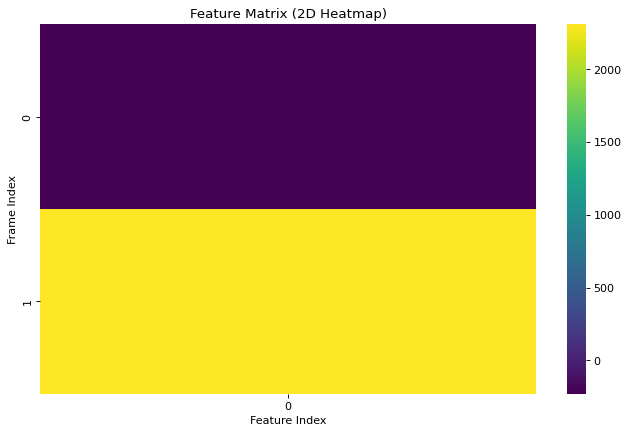

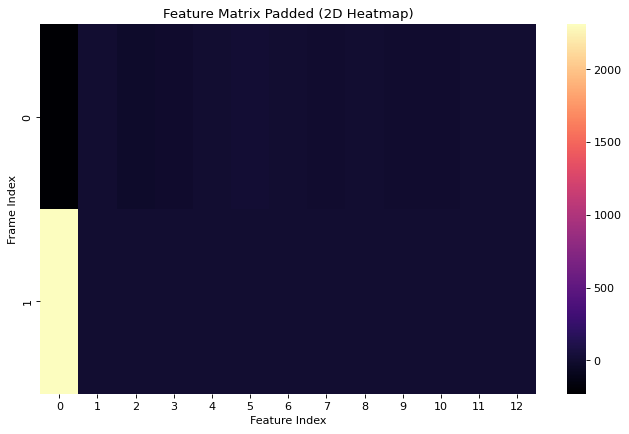

In [8]:
# Visualize feature_matrix (2D heatmap)
plt.figure(figsize=(10, 6))
sns.heatmap(feature_matrix, cmap='viridis', cbar=True)
plt.title('Feature Matrix (2D Heatmap)')
plt.xlabel('Feature Index')
plt.ylabel('Frame Index')
plt.show()
 
# Visualize feature_matrix_padded (2D heatmap)
plt.figure(figsize=(10, 6))
sns.heatmap(feature_matrix_padded, cmap='magma', cbar=True)
plt.title('Feature Matrix Padded (2D Heatmap)')
plt.xlabel('Feature Index')
plt.ylabel('Frame Index')
plt.show()
 